# Projekt

In [20]:
import pandas as pd
from matplotlib import pyplot as plt
from Distributions import BetaDistribution, NormalDistribution, BinDistribution
import numpy as np
import scipy as sp
import scipy.special as sps

In [21]:
Threshold = 6
df = pd.read_csv("ESS11e04_2-subset_filtered.csv")
trust = df["trstplt"]
income = df["hinctnta"]

## A2

In [22]:
def generateVariables(trust,income, Threshold):
    xj = len(income.loc[(trust >= Threshold) & (income <= 3)])
    nj = len(income.loc[income <= 3])
    xk = len(income.loc[(trust >= Threshold) & (income >= 8)])
    nk = len(income.loc[income >= 8])
    return [xj,nj,xk,nk]

In [23]:
[xj,nj,xk,nk] = generateVariables(trust,income, Threshold)

thetaj = xj/nj
thetak = xk/nk

print('Uppgift A2\n')
print(f'Andelen positiva svar i låginkomstgruppen är {round(thetaj,3)}')
print(f'Andelen positiva svar i höginkomstgruppen är {round(thetak,3)}') 
print(f'Skillnaden i andelarna är {round(thetaj-thetak,3)}\n\n')

Uppgift A2

Andelen positiva svar i låginkomstgruppen är 0.194
Andelen positiva svar i höginkomstgruppen är 0.24
Skillnaden i andelarna är -0.046




## A3

In [24]:
def A3_b(xj,nj,xk,nk):

    Betaj = BetaDistribution(xj,nj-xj,10000).generateBetaDistribution() ## E is xj/nj
    Betak = BetaDistribution(xk,nk-xk,10000).generateBetaDistribution()

    Delta = Betaj-Betak
    posDelta = Delta[Delta <= 0]

    bayesDecision = len(posDelta)  / len(Delta)

    # plt.hist(Delta, density=True, bins = 50)
    # plt.show()

    if (bayesDecision <0.5):
        return ['a1', Delta]
    elif (bayesDecision >0.5):
        return ['a0', Delta]
    else:
        return ['Expected loss is equal', Delta]

In [25]:
[decision, DeltaConj] = A3_b(xj,nj,xk,nk)
print('Uppgift A3\n')
print(f'Bayesbeslutet väljer Thetaj>Thetak: {decision}\n\n')

Uppgift A3

Bayesbeslutet väljer Thetaj>Thetak: a0




## A4

In [26]:
def A4_a(xj,xk,nj,nk): ## A4.a) calculation of parameters for prior (logit-normal)

    sigmaSquare = 0.1
    n = 100 ## megaslow be careful
    iter = 10000
    Theta = np.linspace(-10,10,iter)

    expectedGuessJ = 0.15
    expectedGuessK = 0.25

    for i in range(iter):
        Normal = NormalDistribution(Theta[i],sigmaSquare,n).generateNormalDistribution()
        logitNormal = 1/(1+np.exp(-Normal))
        mean = np.mean(logitNormal)
        # print(mean)
        if mean < expectedGuessJ+0.01 and mean > expectedGuessJ-0.01:
            mu_j = Theta[i]
        if mean < expectedGuessK+0.01 and mean > expectedGuessK -0.01:
            mu_k = Theta[i]

    Xj = NormalDistribution(mu_j,sigmaSquare, n).generateNormalDistribution()
    Xk = NormalDistribution(mu_k, sigmaSquare, n).generateNormalDistribution()

    Thetaj = 1/(1+np.exp(-Xj))
    Thetak = 1/(1+np.exp(-Xk))

    ## prior predictives

    rng = np.random.default_rng()

    PriorPredj = np.zeros(n)
    PriorPredk = np.zeros(n)


    for i in range(len(Thetaj)):

        binJ = BinDistribution(nj,Thetaj[i],n).generateBinDistribution()
        binK = BinDistribution(nk,Thetak[i],n).generateBinDistribution()

        PriorPredj[i] = rng.choice(binJ)
        PriorPredk[i] = rng.choice(binK)


    ## Plots of prior predictive vs observed data, use to determine prior parameters
    # plt.figure()
    # plt.hist(PriorPredj,bins = 25, label= "Prior Predictive for j")
    # plt.axvline(xj, color = "green", label = "Observed xj")
    # plt.legend()
    # plt.figure()
    # plt.hist(PriorPredk, bins = 25, label="Prior Predictive for k")
    # plt.axvline(xk, color = "green", label="Observed xk")
    # plt.legend()
    # plt.show()

    return [mu_j, mu_k, sigmaSquare]

In [27]:
def A4_b(xj, xk , nj, nk, mu_j, mu_k,sigmaSquare): ## A4.b) simulation of Posterior

    n = 10000

    Logmj = sp.stats.binom.logpmf(xj, nj, xj / nj)
    Logmk = sp.stats.binom.logpmf(xk, nk, xk / nk)

    PosteriorJ = []
    PosteriorK = []

    max_iter = 1000000
    iter = 0 

    while (len(PosteriorJ) < n) and (iter < max_iter):
        Xj = sp.stats.norm.rvs(loc=mu_j, scale=np.sqrt(sigmaSquare))
        Thetaj = sp.special.expit(Xj) 
        Uj = sp.stats.uniform.rvs()
        if (np.log(Uj)) < sp.stats.binom.logpmf(xj,nj,Thetaj) - Logmj:
            PosteriorJ.append(Thetaj)
        iter+= 1

    if (iter == max_iter):
        print('Rejection sampling did not converge for ThetaJ')

    iter = 0

    while (len(PosteriorK) < n) and (iter < max_iter):
        Xk = sp.stats.norm.rvs(loc=mu_k, scale=np.sqrt(sigmaSquare))
        Thetak = sp.special.expit(Xk)
        Uk = sp.stats.uniform.rvs()
        if (np.log(Uk)) < sp.stats.binom.logpmf(xk,nk,Thetak) - Logmk:
            PosteriorK.append(Thetak)
        iter += 1

    if (iter == max_iter):
            print('Rejection sampling did not converge for ThetaK')

    PosteriorJ = np.array(PosteriorJ)
    PosteriorK = np.array(PosteriorK)


    if (len(PosteriorK) != len(PosteriorK)):
        print('Lengths did not match')
        return
    else:
        return PosteriorJ - PosteriorK

In [28]:
def A4_c(trust, income):
    sampleTrust = trust.sample(n=10, random_state=42)
    sampleIncome = income.sample(n=10, random_state=42)
    [xj,nj,xk,nk] = generateVariables(sampleTrust, sampleIncome, Threshold=6)
    [_, DeltaConj] = A3_b(xj,nj,xk,nk)
    [mu_j, mu_k, sigmaSquare] = A4_a(xj,xk,nj,nk)
    Delta2 = A4_b(xj, xk, nj, nk, mu_j, mu_k, sigmaSquare)
    plt.title('Jämförelse mellan Aposteriori, 10 respondenter')
    plt.hist(DeltaConj, bins = 10, density = True, alpha = 0.6, label='Aposteriori med konjugerad apriori')
    plt.hist(Delta2, bins = 10, density = True, alpha = 0.6, label='Aposteriori med logit-normal apriori')
    plt.legend().set_draggable(True)
    plt.show()

In [29]:
[mu_j, mu_k, sigmaSquare] = A4_a(xj,xk,nj,nk) # very slow, data printed below

## Results of A4_a
# mu_j = -1.6551
# mu_k = -1.0011
# sigmaSquare = 0.1

In [30]:
Delta2 = A4_b(xj, xk, nj, nk, mu_j, mu_k, sigmaSquare)

print('Uppgift A4\n')
print(f'Aposterioriväntevärde för Delta är {np.mean(Delta2)}')
se = Delta2.std(ddof=1) / np.sqrt(len(Delta2)) ## std(ddof=1) ger s^2 = 1/(n-1) Sum (x_i - \bar x)^2
print(f'Montecarlo-medelfelet för förkastelsemetoden är {se}')

print(f'Stickprovsstandardavvikelse: {Delta2.std(ddof=1)}')
print(f'Square root of length: {np.sqrt(len(Delta2))}')

Uppgift A4

Aposterioriväntevärde för Delta är -0.054262718869581034
Montecarlo-medelfelet för förkastelsemetoden är 0.0002655663454818018
Stickprovsstandardavvikelse: 0.02655663454818018
Square root of length: 100.0


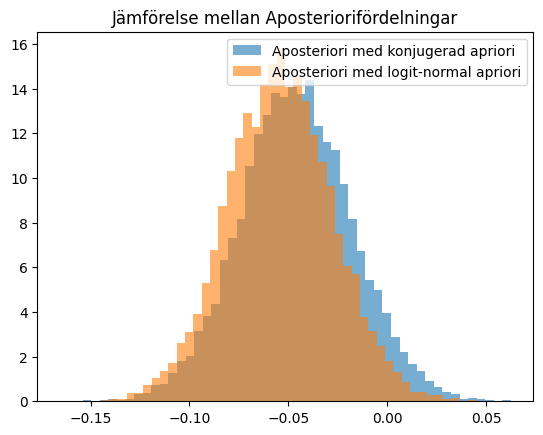

In [31]:
plt.title('Jämförelse mellan Aposteriorifördelningar')
plt.hist(DeltaConj, bins = 50, density = True, alpha = 0.6, label='Aposteriori med konjugerad apriori')
plt.hist(Delta2, bins = 50, density = True, alpha = 0.6, label='Aposteriori med logit-normal apriori')
plt.legend().set_draggable(True)
plt.show()

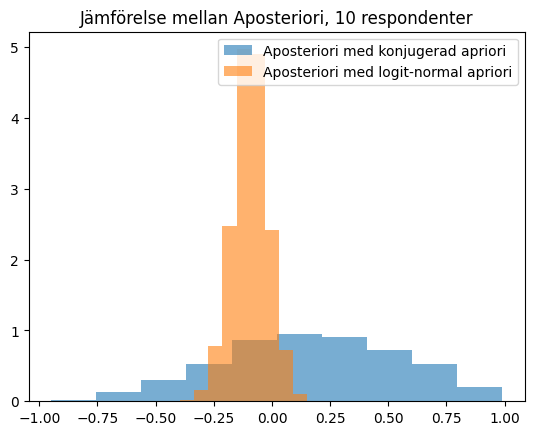

In [32]:
A4_c(trust,income)

## A5

In [33]:
def A5_a(trust, income, Threshold):
    x1 = len(income.loc[(trust >= Threshold) & (income <= 3)])
    n1 = len(income.loc[income <= 3])
    x2 = len(income.loc[(trust >= Threshold) & (income == 4)])
    n2 = len(income.loc[income == 4])
    x3 = len(income.loc[(trust >= Threshold) & (income == 5)])
    n3 = len(income.loc[income == 5])
    x4 = len(income.loc[(trust >= Threshold) & (income == 6)])
    n4 = len(income.loc[income == 6])
    x5 = len(income.loc[(trust >= Threshold) & (income == 7)])
    n5 = len(income.loc[income == 7])
    x6 = len(income.loc[(trust >= Threshold) & (income >= 8)])
    n6 = len(income.loc[income >= 8])

    X = [x1, x2, x3, x4, x5, x6]
    N = [n1, n2, n3, n4, n5, n6]

    return [X,N]

In [34]:
def logpdf(alpha,beta,X,N):
    term1 = (-5/2)*np.log(alpha+beta)
    term2 = len(X)*(sps.loggamma(alpha+beta)-sps.loggamma(alpha)-sps.loggamma(beta))
    term3 = 0
    for i in range(len(X)):
        num = sps.loggamma(X[i]+alpha)+sps.loggamma(beta+N[i]-X[i])
        den = sps.loggamma(alpha+beta+N[i])
        term3 += num - den
    return term1+term2+term3

In [35]:
def invTransformation(gamma,chi):
    alpha = np.exp(gamma+chi) / (1+np.exp(gamma))
    beta =  np.exp(chi) / (1+np.exp(gamma))
    return [alpha,beta]

def Transformation(alpha,beta):
    gamma = np.log(alpha/beta)
    chi = np.log(alpha+beta)
    return [gamma,chi]

def transformedLogPdf(gamma,chi,X,N):
    [alpha,beta] = invTransformation(gamma,chi)
    return logpdf(alpha,beta,X,N)+np.log(alpha)+np.log(beta)

In [36]:
def Metropolis(X,N, iter):
    rng = np.random.default_rng(1223)
    step = 0.5
    Starts = [[1,2],[29,50],[10,15],[6,14]]
    transformedStarts = [Transformation(start[0],start[1]) for start in Starts]    
    chains = []
    for start in transformedStarts:
        chain = np.zeros((iter,2))
        current = np.array(start)
        logpdfCurrent = transformedLogPdf(current[0],current[1],X,N)

        accepted = 0
        for i in range(iter):
            prop = current+step*rng.standard_normal(2)
            logpdfProp = transformedLogPdf(prop[0],prop[1],X,N)

            if np.log(rng.uniform()) < logpdfProp - logpdfCurrent:
                current = prop
                logpdfCurrent = logpdfProp
                accepted+=1

            chain[i] = current

        chains.append(chain)

    return chains

In [ ]:
def A5_b(X,N,endpoint,n):

    Alpha = np.linspace(0.001,endpoint/2,n)
    Beta = np.linspace(0.001,endpoint,n)
    f = np.zeros((n,n))

    for i in range(n):
        beta = Beta[i]
        for j in range(n):
            alpha = Alpha[j]
            f[i][j] = logpdf(alpha,beta,X,N)

    f = f - f.max()
    posDensity =  np.exp(f)

    iter = 1000000
    
    chains = Metropolis(X,N,iter)

    [A, B] = invTransformation(chains[0][cutoff:, 0], chains[0][cutoff:, 1])

    

    ## Generera Theta_j

    Theta = np.zeros((len(X),len(A)))
    rng = np.random.default_rng()
    for j in range(len(X)):
        for i in range(len(A)):
            Theta[j,i] = rng.beta(A[i]+X[j],B[i]+N[j]-X[j])


    return [Alpha, Beta, posDensity, iter, chains, Theta]



In [61]:
def A5_c(X,N,Theta):
    X = np.array(X)
    N = np.array(N)
    thetaHats = X / N

    m1 = sum(thetaHats) / len(thetaHats)
    m2 = sum(thetaHats**2) / len(thetaHats)

    alpha = (m1*(m2-m1)) / (m1**2-m2)
    beta = ((1-m1)*(m2-m1)) / (m1**2-m2)

    PosteriorMeansEmp = (alpha+X) / (alpha+beta+N)
    PosteriorStdEmp = np.sqrt(((alpha+X)*(beta+N-X))/((alpha+beta+N)**2*(alpha+beta+N+1)))
    PosteriorMeansMetro = np.mean(Theta, axis=1)
    PosteriorStdMetro = np.std(Theta,axis=1)

    print(len(PosteriorMeansEmp))
    return [PosteriorMeansEmp, PosteriorStdEmp, PosteriorMeansMetro, PosteriorStdMetro]

In [38]:
[X,N] = A5_a(trust, income, Threshold)
[Alpha, Beta, Density, iter, chains, Theta] = A5_b(X,N,endpoint = 200, n = 1000)

Konturplott av täthetsfunktionen

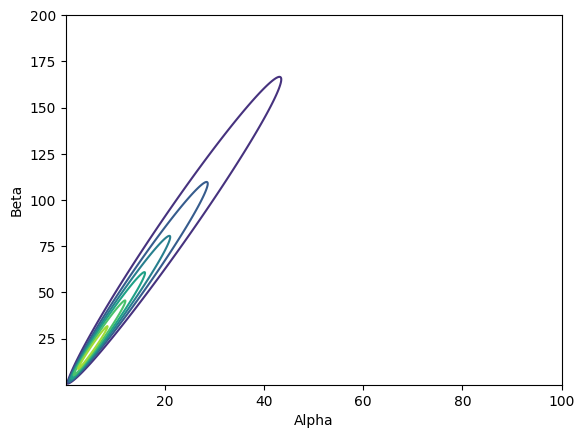

In [39]:
plt.contour(Alpha,Beta, Density)
plt.xlabel("Alpha")
plt.ylabel("Beta")
plt.show()

Plott av Markovkedjor i transformerade koordinater

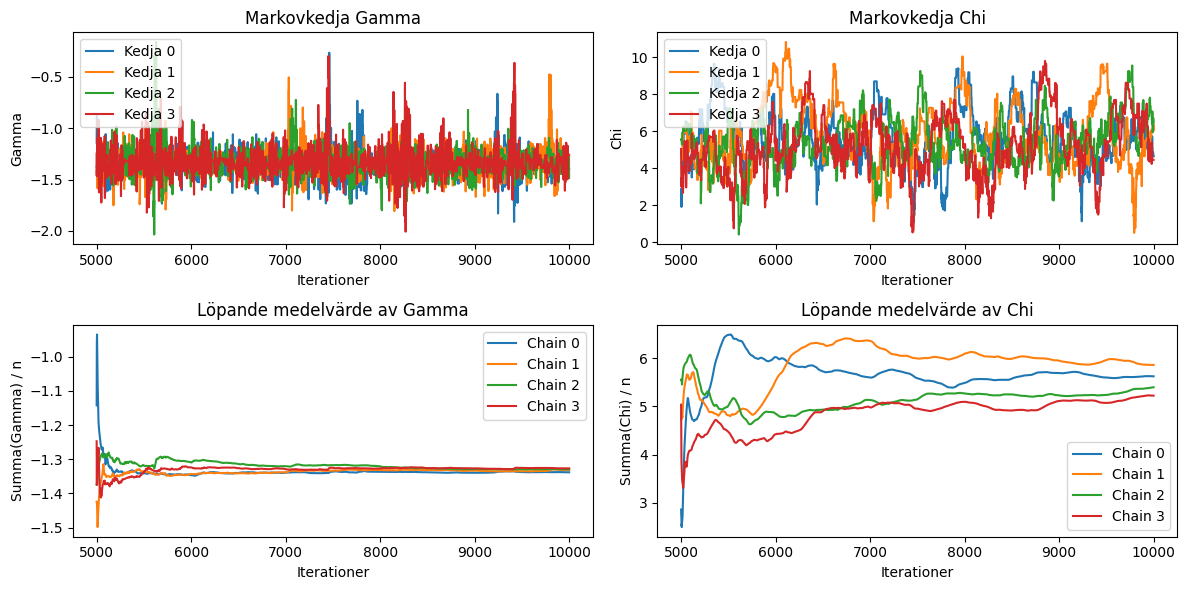

In [40]:
cutoff = round(iter/2)


Arranged = np.arange(1,cutoff+1)
Iters = np.arange(cutoff,iter)

plt.figure(figsize=(12,6))
plt.subplot(2,2,1)
plt.title('Markovkedja Gamma')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,chain[cutoff:,0], label= f'Kedja {i}')
plt.xlabel('Iterationer')
plt.ylabel('Gamma')
plt.legend()

plt.subplot(2,2,2)
plt.title("Markovkedja Chi")
for i in range(4): 
    chain  = chains[i]
    plt.plot(Iters,chain[cutoff:,1], label=f'Kedja {i}')
plt.xlabel('Iterationer')
plt.ylabel('Chi')
plt.legend()

plt.subplot(2,2,3)
plt.title('Löpande medelvärde av Gamma')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,np.cumsum(chain[cutoff:,0]) / Arranged, label=f'Chain {i}')
plt.xlabel('Iterationer')
plt.ylabel('Summa(Gamma) / n')
plt.legend()

plt.subplot(2,2,4)
plt.title('Löpande medelvärde av Chi')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,np.cumsum(chain[cutoff:,1]) / Arranged, label=f'Chain {i}')
plt.xlabel('Iterationer')
plt.ylabel('Summa(Chi) / n')
plt.legend()

plt.tight_layout()
plt.show()

Plott av Theta för alla grupper

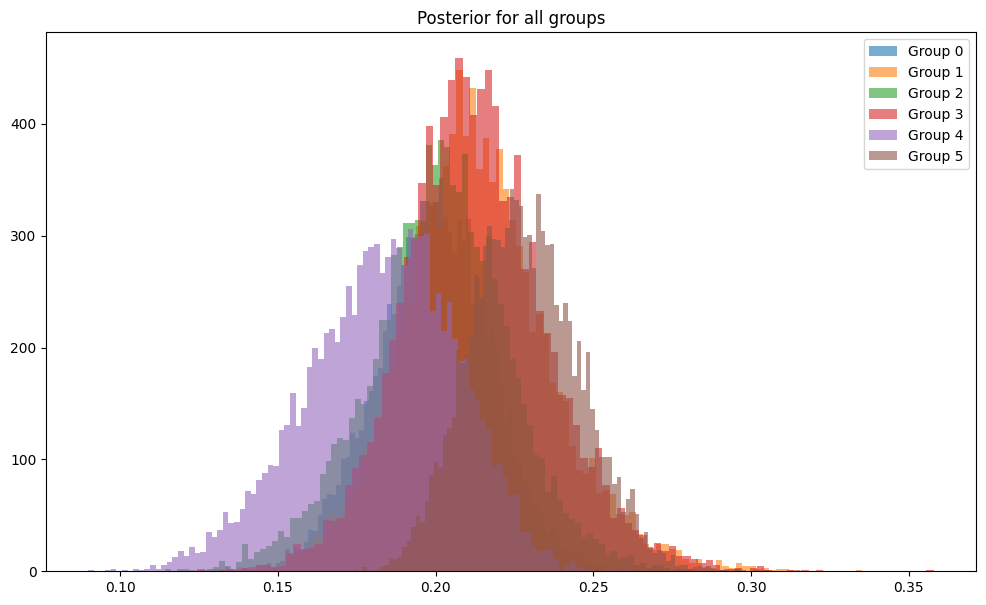

In [41]:
plt.figure(figsize=(12,7))
plt.title('Posterior for all groups')
for j in range(len(Theta)):
    plt.hist(Theta[j], bins=100, alpha=0.6, label = f'Group {j}')
plt.legend()
plt.show()

Jämförelse med Empirisk Bayes

6


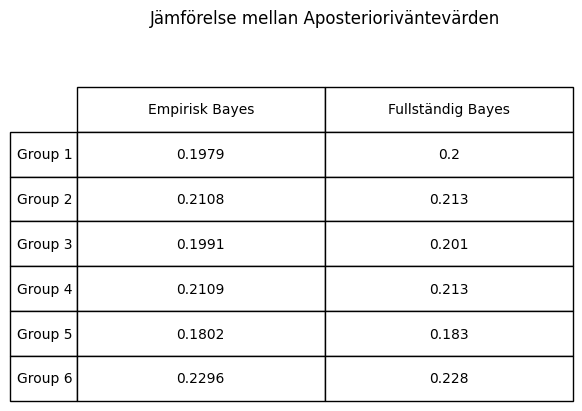

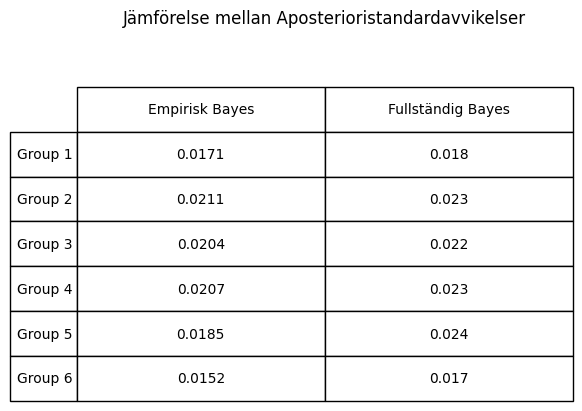

In [ ]:
[EmpMean, EmpStd, MetroMean, MetroStd] = A5_c(X,N,Theta)

fig1,ax1 = plt.subplots()
ax1.axis("off")
ax1.set_title('Jämförelse mellan Aposterioriväntevärden')
ax1.table(
    cellText=[[round(EmpMean[i],4), round(MetroMean[i],3)] for i in range(len(EmpMean))],
    colLabels=['Empirisk Bayes', 'Fullständig Bayes'],
    rowLabels=[f'Group {i+1}' for i in range(len(EmpMean))],
    loc='center',
    cellLoc='center',
    bbox = [0,0,1,0.85]
)
fig2,ax2 = plt.subplots()
ax2.axis("off")
ax2.set_title('Jämförelse mellan Aposterioristandardavvikelser')
ax2.table(
    cellText=[[round(EmpStd[i],4), round(MetroStd[i],3)] for i in range(len(EmpMean))],
    colLabels=['Empirisk Bayes', 'Fullständig Bayes'],
    rowLabels=[f'Grupp {i+1}' for i in range(len(EmpStd))],
    loc='center',
    cellLoc='center',
    bbox = [0,0,1,0.85]
)
plt.show()